# 1. Project Overview

This notebook audits the local datasets used by the SecureGuard spam and malware detection project, performs exploratory data analysis (EDA), checks data quality, compares candidate classifiers using validation data, evaluates the selected models on a separate final test set, and saves compatible model artifacts.

**Reproducibility note:** this notebook reads local CSV files from the project data directory. Dataset provenance is recorded as unverified unless the repository contains evidence that confirms it. Run the notebook from top to bottom to regenerate all tables, charts, metrics, and saved artifacts.

**Evaluation principle:** do not select models using final test-set results. The test set is reserved for the final evaluation after selection on validation data.


## 2. Environment and Imports

The next setup cell imports the libraries used below, resolves the data directory relative to the notebook's working directory, and defines shared label/text preparation helpers. Run the notebook from top to bottom so later analysis and prediction cells use the same settings.

## 3. Dataset Provenance

This section distinguishes repository evidence from possible attribution. The candidate references below are inherited metadata notes only; neither a filename nor a matching schema proves origin, collection method, license, or whether the malware records are real telemetry. SHA-256 values in the inspection table identify the local files for reproducibility, not their source.

In [2]:
from pathlib import Path
import json

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import (
    adjusted_rand_score,
    classification_report,
    confusion_matrix,
    normalized_mutual_info_score,
    roc_auc_score,
    silhouette_score,
)
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

RANDOM_STATE = 42
USE_MULTILINGUAL_AUGMENTATION = False


def resolve_data_dir() -> Path:
    cwd = Path.cwd().resolve()
    candidates = [cwd, cwd / 'data', cwd.parent / 'data']
    for candidate in candidates:
        if (candidate / 'mail_data.csv').exists() and (candidate / 'Malware dataset.csv').exists():
            return candidate
    raise FileNotFoundError('Could not locate the data directory that contains the training CSV files.')


DATA_DIR = resolve_data_dir()
MODEL_DIR = DATA_DIR / 'trained_models'
MODEL_DIR.mkdir(exist_ok=True)

# These candidate attributions are inherited notes, not verified dataset provenance.
DATA_SOURCES = [
    {
        'local_file': 'mail_data.csv',
        'task': 'spam_classification',
        'candidate_origin': 'Possible UCI SMS Spam Collection match (unverified)',
        'candidate_reference': 'https://archive.ics.uci.edu/ml/datasets/SMS+Spam+Collection',
        'provenance_status': 'unverified',
    },
    {
        'local_file': 'emails.csv',
        'task': 'spam_classification',
        'candidate_origin': 'Possible open email spam/ham corpus (unverified)',
        'candidate_reference': 'https://www.cs.cmu.edu/~enron/',
        'provenance_status': 'unverified',
    },
    {
        'local_file': 'data-augmented.csv',
        'task': 'spam_classification_multilingual',
        'candidate_origin': 'Possible derivative/augmentation of an open spam corpus (unverified)',
        'candidate_reference': 'https://archive.ics.uci.edu/ml/datasets/SMS+Spam+Collection',
        'provenance_status': 'unverified',
    },
    {
        'local_file': 'Malware dataset.csv',
        'task': 'malware_classification',
        'candidate_origin': 'Origin not established by repository evidence',
        'candidate_reference': None,
        'provenance_status': 'unverified',
    },
]

print(f'Data directory: {DATA_DIR}')
print(f'Model output directory: {MODEL_DIR}')
print('\nCandidate dataset attributions (all unverified):')
pd.DataFrame(DATA_SOURCES)


def normalize_binary_label(value):
    if pd.isna(value):
        return np.nan

    normalized = str(value).strip().lower()
    if normalized in {'spam', 'malware', '1', 'true', 'yes'}:
        return 1
    if normalized in {'ham', 'benign', '0', 'false', 'no'}:
        return 0

    try:
        numeric_value = int(float(normalized))
    except ValueError:
        return np.nan

    return numeric_value if numeric_value in {0, 1} else np.nan


def normalize_text_key(series: pd.Series) -> pd.Series:
    """Create an audit-only key: lowercase text and collapse repeated whitespace."""
    return (
        series.astype('string')
        .str.lower()
        .str.replace(r'\s+', ' ', regex=True)
        .str.strip()
    )


def finalize_text_frame(frame: pd.DataFrame, source_name: str) -> pd.DataFrame:
    prepared = frame.copy()
    # Preserve nulls through string conversion so missing values cannot become usable-looking "nan" messages.
    prepared['text'] = prepared['text'].astype('string').str.strip()
    prepared['label'] = prepared['label'].map(normalize_binary_label)
    prepared = prepared.dropna(subset=['text', 'label'])
    prepared = prepared[prepared['text'] != '']
    prepared['label'] = prepared['label'].astype(int)
    prepared['text_length'] = prepared['text'].str.len()
    prepared['source'] = source_name
    return prepared[['text', 'label', 'text_length', 'source']]


def load_mail_data(path: Path) -> pd.DataFrame:
    frame = read_csv_with_encoding(path)
    return finalize_text_frame(
        frame[['Message', 'Category']].rename(columns={'Message': 'text', 'Category': 'label'}),
        path.name,
    )


def load_emails_data(path: Path) -> pd.DataFrame:
    frame = read_csv_with_encoding(path)
    return finalize_text_frame(
        frame[['text', 'spam']].rename(columns={'spam': 'label'}),
        path.name,
    )


def load_augmented_data(path: Path, include_multilingual: bool = False) -> pd.DataFrame:
    frame = pd.read_csv(path)
    text_columns = ['text']
    if include_multilingual:
        text_columns.extend([column for column in frame.columns if column.startswith('text_')])

    prepared_frames = []
    for column in text_columns:
        prepared_frames.append(
            finalize_text_frame(
                frame[['labels', column]].rename(columns={'labels': 'label', column: 'text'}),
                f'{path.name}:{column}',
            )
        )

    return pd.concat(prepared_frames, ignore_index=True)

Data directory: D:\COS30049\group-project-spr-2026-grp2_7\data
Model output directory: D:\COS30049\group-project-spr-2026-grp2_7\data\trained_models

Candidate dataset attributions (all unverified):


## 4. Initial Data Inspection

The inventory below reads the local CSV files to report their schemas, row counts, missing cells, exact duplicate rows, file sizes, and SHA-256 hashes. It helps catch input drift and creates a reproducible local fingerprint; none of these checks establishes dataset provenance.

In [3]:
import hashlib

CSV_ENCODINGS = {}


def read_csv_with_encoding(path: Path) -> pd.DataFrame:
    try:
        frame = pd.read_csv(path, encoding='utf-8-sig')
        CSV_ENCODINGS[path.name] = 'utf-8-sig'
    except UnicodeDecodeError:
        # One repository CSV is Windows-1252; record this fallback so its use is visible in EDA.
        frame = pd.read_csv(path, encoding='cp1252')
        CSV_ENCODINGS[path.name] = 'cp1252'
    return frame


def sha256_file(path: Path) -> str:
    digest = hashlib.sha256()
    with path.open('rb') as file:
        for chunk in iter(lambda: file.read(1024 * 1024), b''):
            digest.update(chunk)
    return digest.hexdigest()


training_input_names = {source['local_file'] for source in DATA_SOURCES}
inventory_rows = []
for csv_path in sorted(DATA_DIR.glob('*.csv')):
    frame = read_csv_with_encoding(csv_path)
    inventory_rows.append(
        {
            'file': csv_path.name,
            'used_for_training': csv_path.name in training_input_names,
            'encoding': CSV_ENCODINGS[csv_path.name],
            'rows': len(frame),
            'columns': ', '.join(frame.columns.astype(str)),
            'missing_cells': int(frame.isna().sum().sum()),
            'exact_duplicate_rows': int(frame.duplicated().sum()),
            'size_bytes': csv_path.stat().st_size,
            'sha256': sha256_file(csv_path),
        }
    )

file_inventory = pd.DataFrame(inventory_rows)
print(f'Inspected {len(file_inventory)} CSV files in {DATA_DIR}')
display(file_inventory)
missing_training_files = sorted(training_input_names - set(file_inventory['file']))
print('Missing declared training inputs:', missing_training_files)
if missing_training_files:
    raise FileNotFoundError(f'Missing declared training inputs: {missing_training_files}')

Inspected 7 CSV files in D:\COS30049\group-project-spr-2026-grp2_7\data


,file,used_for_training,encoding,rows,columns,missing_cells,exact_duplicate_rows,size_bytes,sha256
0,data-augmented.csv,True,utf-8-sig,5572,"Unnamed: 0, labels, text, text_hi, text_de, te...",83,0,14234243,f90ca26ca52ca65acdb71c1d73bf1d1c3806bb12f9489a...
1,emails.csv,True,utf-8-sig,5728,"text, spam",0,33,8960484,52c5305aa14dccda9735e4b9a821604cc2893914b3d8de...
2,mail_data.csv,True,utf-8-sig,5613,"Category, Message",0,425,488906,de1d0960b108190a347fcf7918110b9f87d7d0a5773f6e...
3,mail_dataset.csv,False,utf-8-sig,6018,"text, label",0,5960,246871,a7a6be15173f7d9d85365e806b987df3894622b0b386d2...
4,Malware dataset.csv,True,utf-8-sig,100000,"hash, millisecond, classification, state, usag...",0,0,18105021,b1464504a4354ebe7c982bd41bdeb57b1b3c75c0acd498...
5,Malwaredataset.csv,False,utf-8-sig,100000,"hash, millisecond, classification, state, usag...",0,0,18105021,b1464504a4354ebe7c982bd41bdeb57b1b3c75c0acd498...
6,spam.csv,False,cp1252,5572,"v1, v2, Unnamed: 2, Unnamed: 3, Unnamed: 4",16648,403,503663,440e6ea9fa825578abfdd7b7932ef8393d72ef86c0c33f...


Missing declared training inputs: []


## 5. Spam Dataset EDA

This pass compares each selected spam source before cross-source deduplication. It reports raw versus usable rows, missing/blank messages, unrecognized labels, class counts, and message-length patterns so cleaning effects are visible rather than hidden.

Spam source quality and label counts:


,source,raw_rows,usable_rows,rows_not_used,missing_text,blank_text,unrecognized_or_missing_labels,ham_rows,spam_rows
0,mail_data.csv,5613,5613,0,0,0,0,4845,768
1,emails.csv,5728,5728,0,0,0,0,4360,1368
2,data-augmented.csv,5572,5572,0,0,0,0,4825,747


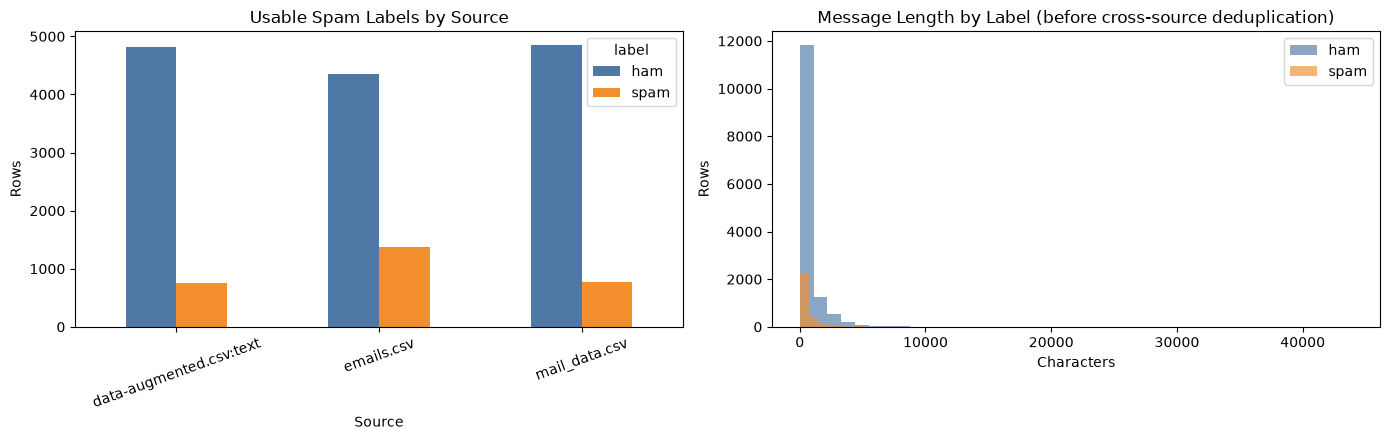

Source-level EDA counts only normalized, nonblank records; cross-source duplicates are audited next.


In [4]:
raw_spam_data = {
    'mail_data.csv': read_csv_with_encoding(DATA_DIR / 'mail_data.csv'),
    'emails.csv': read_csv_with_encoding(DATA_DIR / 'emails.csv'),
    'data-augmented.csv': read_csv_with_encoding(DATA_DIR / 'data-augmented.csv'),
}
spam_source_frames = [
    load_mail_data(DATA_DIR / 'mail_data.csv'),
    load_emails_data(DATA_DIR / 'emails.csv'),
    load_augmented_data(
        DATA_DIR / 'data-augmented.csv',
        include_multilingual=USE_MULTILINGUAL_AUGMENTATION,
    ),
]

spam_source_specs = [
    ('mail_data.csv', raw_spam_data['mail_data.csv'], 'Message', 'Category', spam_source_frames[0]),
    ('emails.csv', raw_spam_data['emails.csv'], 'text', 'spam', spam_source_frames[1]),
    ('data-augmented.csv', raw_spam_data['data-augmented.csv'], 'text', 'labels', spam_source_frames[2]),
]
source_quality_rows = []
for source_name, raw_frame, text_column, label_column, cleaned_frame in spam_source_specs:
    normalized_labels = raw_frame[label_column].map(normalize_binary_label)
    blank_text_mask = raw_frame[text_column].astype('string').str.strip().eq('').fillna(False)
    source_quality_rows.append(
        {
            'source': source_name,
            'raw_rows': len(raw_frame),
            'usable_rows': len(cleaned_frame),
            'rows_not_used': len(raw_frame) - len(cleaned_frame),
            'missing_text': int(raw_frame[text_column].isna().sum()),
            'blank_text': int(blank_text_mask.sum()),
            'unrecognized_or_missing_labels': int(normalized_labels.isna().sum()),
            'ham_rows': int((cleaned_frame['label'] == 0).sum()),
            'spam_rows': int((cleaned_frame['label'] == 1).sum()),
        }
    )

spam_source_quality = pd.DataFrame(source_quality_rows)
print('Spam source quality and label counts:')
display(spam_source_quality)

spam_eda_rows = pd.concat(spam_source_frames, ignore_index=True)
source_class_counts = (
    spam_eda_rows.groupby(['source', 'label']).size().unstack(fill_value=0)
    .rename(columns={0: 'ham', 1: 'spam'})
)
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
source_class_counts.plot(kind='bar', ax=axes[0], color=['#4e79a7', '#f28e2b'])
axes[0].set_title('Usable Spam Labels by Source')
axes[0].set_xlabel('Source')
axes[0].set_ylabel('Rows')
axes[0].tick_params(axis='x', rotation=20)

for label_value, label_name, color in [(0, 'ham', '#4e79a7'), (1, 'spam', '#f28e2b')]:
    axes[1].hist(
        spam_eda_rows.loc[spam_eda_rows['label'] == label_value, 'text_length'],
        bins=40,
        alpha=0.65,
        label=label_name,
        color=color,
    )
axes[1].set_title('Message Length by Label (before cross-source deduplication)')
axes[1].set_xlabel('Characters')
axes[1].set_ylabel('Rows')
axes[1].legend()
plt.tight_layout()
plt.show()

print('Source-level EDA counts only normalized, nonblank records; cross-source duplicates are audited next.')

## 6. Duplicate and Conflicting Label Analysis

This audit distinguishes exact raw text matches from normalized-text matches. The normalized key is used only to identify likely duplicates: lowercase text and collapse repeated whitespace. The original message text is preserved for model training and traceability.

Records sharing a normalized key but carrying different labels are flagged as conflicting. They are excluded as a group from the primary spam experiment rather than silently relabeled. This is an exact/normalized duplicate audit, not a semantic near-duplicate detector.


In [5]:
spam_records = pd.concat(spam_source_frames, ignore_index=True)

# Preserve original text; use a separate normalized key only for duplicate/conflict auditing.
spam_records['normalized_text'] = normalize_text_key(spam_records['text'])
spam_records = spam_records.loc[
    spam_records['normalized_text'].notna() & spam_records['normalized_text'].ne('')
].copy()

exact_duplicate_mask = spam_records.duplicated(subset=['text', 'label'], keep='first')
spam_exact_duplicate_rows = int(exact_duplicate_mask.sum())

normalized_duplicate_mask = spam_records.duplicated(subset=['normalized_text', 'label'], keep='first')
spam_normalized_duplicate_rows = int(normalized_duplicate_mask.sum())

label_count_by_normalized_text = spam_records.groupby('normalized_text', sort=False)['label'].nunique()
spam_conflicting_texts = set(label_count_by_normalized_text[label_count_by_normalized_text > 1].index)
conflict_record_mask = spam_records['normalized_text'].isin(spam_conflicting_texts)
spam_conflict_records = spam_records.loc[conflict_record_mask].copy()
spam_conflict_group_count = len(spam_conflicting_texts)
spam_conflict_row_count = int(conflict_record_mask.sum())

spam_conflict_audit = (
    spam_conflict_records.groupby('normalized_text', sort=False)
    .agg(
        rows=('label', 'size'),
        labels=('label', lambda labels: ','.join(map(str, sorted(labels.unique())))),
        sources=('source', lambda values: ', '.join(sorted(set(values)))),
        text_length=('text_length', 'first'),
    )
    .reset_index()
)
spam_conflict_audit['normalized_text_sha256_prefix'] = spam_conflict_audit['normalized_text'].map(
    lambda text: hashlib.sha256(text.encode('utf-8')).hexdigest()[:12]
)
# Do not display full message bodies in the audit output.
spam_conflict_audit = spam_conflict_audit.drop(columns='normalized_text').sort_values(
    ['rows', 'sources'], ascending=False
).reset_index(drop=True)

print(f'Usable source records before integration: {len(spam_records):,}')
print(f'Exact duplicate (original text, label) rows beyond first occurrence: {spam_exact_duplicate_rows:,}')
print(f'Normalized duplicate (normalized text, label) rows beyond first occurrence: {spam_normalized_duplicate_rows:,}')
print(f'Conflicting normalized-text groups: {spam_conflict_group_count:,}')
print(f'Records in conflicting normalized-text groups: {spam_conflict_row_count:,}')
display(spam_conflict_audit.head(20))
if spam_conflict_group_count == 0:
    print('Interpretation: no normalized text key was assigned both ham and spam in the loaded sources.')
else:
    print('Interpretation: conflicting normalized-text groups were detected; all records in those groups are excluded from the primary experiment.')


Usable source records before integration: 16,913
Exact duplicate (original text, label) rows beyond first occurrence: 5,982
Normalized duplicate (normalized text, label) rows beyond first occurrence: 6,147
Conflicting normalized-text groups: 0
Records in conflicting normalized-text groups: 0


,rows,labels,sources,text_length,normalized_text_sha256_prefix


Interpretation: no normalized text key was assigned both ham and spam in the loaded sources.


## 7. Spam Data Cleaning and Integration

The training frame is built from the usable source records. Contradictory text groups are removed as a documented quality decision, then exact same-label duplicates are collapsed; counts before and after each operation are shown. No processed CSV is written, and the source files are not modified.

Spam integration row counts:


,stage,rows
0,usable source records,16913
1,after conflicting normalized-text exclusion,16913
2,after normalized duplicate removal,10766


Conflicting-label records excluded: 0
Exact duplicate rows removed after conflict exclusion: 5,982
Normalized duplicate rows removed after conflict exclusion: 6,147
Final spam training rows: 10,766
Final spam label distribution:


,rows
label,
ham,8729
spam,2037


Final spam source distribution (first retained source for duplicate normalized text):


,rows
source,
emails.csv,5532
mail_data.csv,5186
data-augmented.csv:text,48


Final message-length summary by class:


,count,mean,median,std
label,,,,
ham,8729,815.888418,154.0,1580.503309
spam,2037,927.849288,405.0,1941.933628


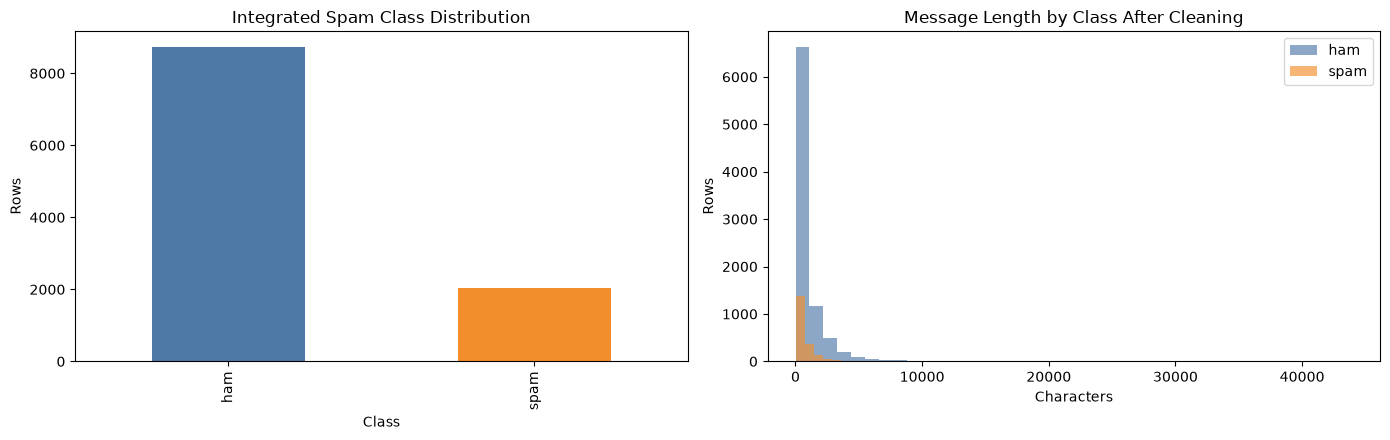

Interpretation: normalized duplicates and contradictory normalized-text groups were handled before the model split.


In [6]:
spam_after_conflict_filter = spam_records.loc[
    ~spam_records['normalized_text'].isin(spam_conflicting_texts)
].copy()
spam_conflict_rows_excluded = len(spam_records) - len(spam_after_conflict_filter)

spam_exact_duplicates_removed = int(
    spam_after_conflict_filter.duplicated(subset=['text', 'label'], keep='first').sum()
)
spam_normalized_duplicates_removed = int(
    spam_after_conflict_filter.duplicated(subset=['normalized_text', 'label'], keep='first').sum()
)

spam_df = (
    spam_after_conflict_filter
    .drop_duplicates(subset=['normalized_text', 'label'])
    .drop(columns=['normalized_text'])
    .sample(frac=1.0, random_state=RANDOM_STATE)
    .reset_index(drop=True)
)
spam_cleaning_summary = pd.DataFrame(
    [
        {'stage': 'usable source records', 'rows': len(spam_records)},
        {'stage': 'after conflicting normalized-text exclusion', 'rows': len(spam_after_conflict_filter)},
        {'stage': 'after normalized duplicate removal', 'rows': len(spam_df)},
    ]
)
print('Spam integration row counts:')
display(spam_cleaning_summary)
print(f'Conflicting-label records excluded: {spam_conflict_rows_excluded:,}')
print(f'Exact duplicate rows removed after conflict exclusion: {spam_exact_duplicates_removed:,}')
print(f'Normalized duplicate rows removed after conflict exclusion: {spam_normalized_duplicates_removed:,}')
print(f'Final spam training rows: {len(spam_df):,}')

spam_label_distribution = spam_df['label'].value_counts().rename(index={0: 'ham', 1: 'spam'})
print('Final spam label distribution:')
display(spam_label_distribution.to_frame('rows'))
print('Final spam source distribution (first retained source for duplicate normalized text):')
display(spam_df['source'].value_counts().to_frame('rows'))

spam_summary = (
    spam_df.groupby('label')['text_length']
    .agg(['count', 'mean', 'median', 'std'])
    .rename(index={0: 'ham', 1: 'spam'})
)
print('Final message-length summary by class:')
display(spam_summary)

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
spam_label_distribution.plot(kind='bar', ax=axes[0], color=['#4e79a7', '#f28e2b'])
axes[0].set_title('Integrated Spam Class Distribution')
axes[0].set_xlabel('Class')
axes[0].set_ylabel('Rows')

for label_value, label_name, color in [(0, 'ham', '#4e79a7'), (1, 'spam', '#f28e2b')]:
    axes[1].hist(
        spam_df.loc[spam_df['label'] == label_value, 'text_length'],
        bins=40, alpha=0.65, label=label_name, color=color
    )
axes[1].set_title('Message Length by Class After Cleaning')
axes[1].set_xlabel('Characters')
axes[1].set_ylabel('Rows')
axes[1].legend()
plt.tight_layout()
plt.show()

if len(spam_df) == 0:
    raise ValueError('No spam records remain after the documented cleaning steps.')
if spam_df['text'].isna().any() or spam_df['label'].isna().any():
    raise AssertionError('The cleaned spam frame contains missing text or labels.')
if spam_df['label'].nunique() != 2:
    raise ValueError('Spam classification requires both ham and spam classes after cleaning.')
if normalize_text_key(spam_df['text']).duplicated().any():
    raise AssertionError('Normalized duplicate message text remains after integration.')
print('Interpretation: normalized duplicates and contradictory normalized-text groups were handled before the model split.')


In [7]:
print('Sample of the integrated spam training frame (message bodies omitted):')
display(spam_df[['label', 'text_length', 'source']].head())

Sample of the integrated spam training frame (message bodies omitted):


,label,text_length,source
0,0,984,emails.csv
1,0,2992,emails.csv
2,0,23,mail_data.csv
3,0,133,mail_data.csv
4,0,1461,emails.csv


### Spam Model Training and Evaluation

The spam experiment uses a three-way split: 60% training, 20% validation, and 20% final test data. Candidate models are fitted on the training partition and selected using validation ROC-AUC. The selected pipeline is then refitted on training plus validation data and evaluated once on the held-out test set.

TF-IDF is fitted inside each pipeline, so vocabulary learning happens only on the relevant training partition. This reduces preprocessing leakage. The test set is not used to choose the model.


In [8]:
# Reproducible 60/20/20 stratified split: train, validation, final test.
X_trainval_text, X_test_text, y_trainval_text, y_test_text = train_test_split(
    spam_df['text'],
    spam_df['label'],
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=spam_df['label'],
)
X_train_text, X_val_text, y_train_text, y_val_text = train_test_split(
    X_trainval_text,
    y_trainval_text,
    test_size=0.25,  # 25% of the 80% remainder = 20% of the complete dataset
    random_state=RANDOM_STATE,
    stratify=y_trainval_text,
)

spam_models = {
    'logistic_regression_char_tfidf': Pipeline(
        steps=[
            ('tfidf', TfidfVectorizer(
                analyzer='char_wb', ngram_range=(3, 5), min_df=2, sublinear_tf=True
            )),
            ('classifier', LogisticRegression(
                max_iter=2000, class_weight='balanced', random_state=RANDOM_STATE
            )),
        ]
    ),
    'logistic_regression_word_tfidf': Pipeline(
        steps=[
            ('tfidf', TfidfVectorizer(
                analyzer='word', ngram_range=(1, 2), min_df=3, max_features=30000
            )),
            ('classifier', LogisticRegression(
                max_iter=1500, class_weight='balanced', C=0.8, random_state=RANDOM_STATE
            )),
        ]
    ),
    'multinomial_naive_bayes_word_tfidf': Pipeline(
        steps=[
            ('tfidf', TfidfVectorizer(
                analyzer='word', ngram_range=(1, 2), min_df=2, max_features=30000
            )),
            ('classifier', MultinomialNB(alpha=0.5)),
        ]
    ),
}

spam_validation_rows = []
for model_name, model_pipeline in spam_models.items():
    model_pipeline.fit(X_train_text, y_train_text)
    val_predictions = model_pipeline.predict(X_val_text)
    val_probabilities = model_pipeline.predict_proba(X_val_text)[:, 1]
    val_report = classification_report(
        y_val_text, val_predictions, labels=[0, 1],
        target_names=['ham', 'spam'], output_dict=True, zero_division=0
    )
    spam_validation_rows.append({
        'model': model_name,
        'accuracy': val_report['accuracy'],
        'spam_precision': val_report['spam']['precision'],
        'spam_recall': val_report['spam']['recall'],
        'spam_f1': val_report['spam']['f1-score'],
        'roc_auc': roc_auc_score(y_val_text, val_probabilities),
    })

spam_validation_df = (
    pd.DataFrame(spam_validation_rows)
    .sort_values('roc_auc', ascending=False)
    .reset_index(drop=True)
)
print('Spam candidate comparison on validation data (not the final test set):')
display(spam_validation_df.round(4))

best_spam_model_name = str(spam_validation_df.iloc[0]['model'])
spam_pipeline = spam_models[best_spam_model_name]

# Refit the selected pipeline on all development data, leaving the final test untouched.
spam_pipeline.fit(X_trainval_text, y_trainval_text)
spam_predictions = spam_pipeline.predict(X_test_text)
spam_probabilities = spam_pipeline.predict_proba(X_test_text)[:, 1]
spam_test_report = classification_report(
    y_test_text, spam_predictions, labels=[0, 1],
    target_names=['ham', 'spam'], output_dict=True, zero_division=0
)

print(f'Selected spam model by validation ROC-AUC: {best_spam_model_name}')
print('Final held-out spam test classification report:')
print(classification_report(
    y_test_text, spam_predictions, labels=[0, 1],
    target_names=['ham', 'spam'], zero_division=0
))
print(f'Final spam test ROC-AUC: {roc_auc_score(y_test_text, spam_probabilities):.4f}')

spam_confusion = pd.DataFrame(
    confusion_matrix(y_test_text, spam_predictions, labels=[0, 1]),
    index=['actual_ham', 'actual_spam'],
    columns=['predicted_ham', 'predicted_spam'],
)
display(spam_confusion)

spam_split_summary = pd.DataFrame([
    {'partition': 'train', 'rows': len(X_train_text), 'spam_rate': float(y_train_text.mean())},
    {'partition': 'validation', 'rows': len(X_val_text), 'spam_rate': float(y_val_text.mean())},
    {'partition': 'final_test', 'rows': len(X_test_text), 'spam_rate': float(y_test_text.mean())},
])
print('Spam split sizes and positive-class rates:')
display(spam_split_summary)


Spam candidate comparison on validation data (not the final test set):


,model,accuracy,spam_precision,spam_recall,spam_f1,roc_auc
0,logistic_regression_char_tfidf,0.9810,0.9378,0.9631,0.9503,0.9957
1,logistic_regression_word_tfidf,0.9749,0.9253,0.9435,0.9343,0.9949
2,multinomial_naive_bayes_word_tfidf,0.9577,0.9907,0.7838,0.8752,0.9891


Selected spam model by validation ROC-AUC: logistic_regression_char_tfidf
Final held-out spam test classification report:
              precision    recall  f1-score   support

         ham       0.99      0.99      0.99      1746
        spam       0.96      0.96      0.96       408

    accuracy                           0.98      2154
   macro avg       0.97      0.98      0.98      2154
weighted avg       0.98      0.98      0.98      2154

Final spam test ROC-AUC: 0.9971


,predicted_ham,predicted_spam
actual_ham,1729,17
actual_spam,16,392


Spam split sizes and positive-class rates:


,partition,rows,spam_rate
0,train,6459,0.189193
1,validation,2153,0.189039
2,final_test,2154,0.189415


## 8. Malware Dataset EDA and Classification

The malware CSV's provenance is not established by its filename alone. This section audits label quality, missing and non-numeric values, duplicate feature vectors, and suspicious feature/label associations before classification.

For a fair evaluation, candidate classifiers are selected using validation data and the final score is reported on a separate held-out test partition. A very high score is treated as a reason to investigate data quality and potential leakage, not as automatic proof of real-world performance.


Raw malware label values:


,rows
classification,
malware,50000
benign,50000


Rows excluded for missing or unrecognized labels: 0
Numeric feature columns initially available: 33
All-missing numeric columns excluded: []
Non-numeric columns excluded from modeling: []
Missing numeric feature cells before imputation: 0
Exact duplicate feature/label rows observed before deduplication: 0
Conflicting identical-feature groups excluded: 0
Rows excluded from conflicting feature groups: 0
Repeated feature rows removed after conflict exclusion: 0
Usable malware rows after audit and deduplication: 100,000
Numeric model features retained: 33
Usable malware class distribution:


,rows
_label,
malware,50000
benign,50000


Top absolute numeric feature/label correlations (investigate unusually strong values):


,pearson_correlation
nvcsw,-0.386889
utime,-0.369931
vm_truncate_count,-0.354861
shared_vm,-0.324954
end_data,-0.324954
maj_flt,-0.324954
static_prio,-0.317941
map_count,-0.271227
exec_vm,-0.255123
nivcsw,-0.143791


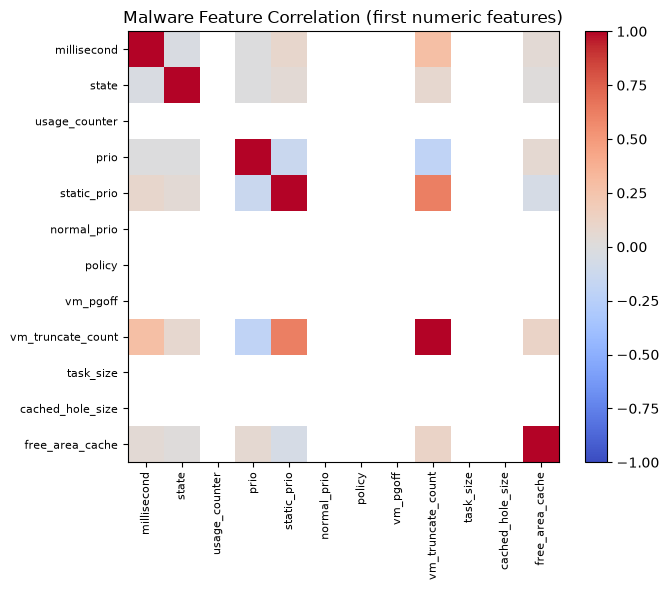

Malware candidate comparison on validation data (not the final test set):


,model,accuracy,malware_precision,malware_recall,malware_f1,roc_auc
0,random_forest,1.0000,1.0,1.0000,1.0000,1.0000
1,decision_tree_baseline,0.9998,1.0,0.9997,0.9998,0.9998


Selected malware model by validation ROC-AUC: random_forest
Final held-out malware test classification report:
              precision    recall  f1-score   support

      benign       1.00      1.00      1.00     10000
     malware       1.00      1.00      1.00     10000

    accuracy                           1.00     20000
   macro avg       1.00      1.00      1.00     20000
weighted avg       1.00      1.00      1.00     20000

Final malware test ROC-AUC: 1.0000


,predicted_benign,predicted_malware
actual_benign,10000,0
actual_malware,0,10000


Malware split sizes and positive-class rates:


,partition,rows,malware_rate
0,train,60000,0.5
1,validation,20000,0.5
2,final_test,20000,0.5


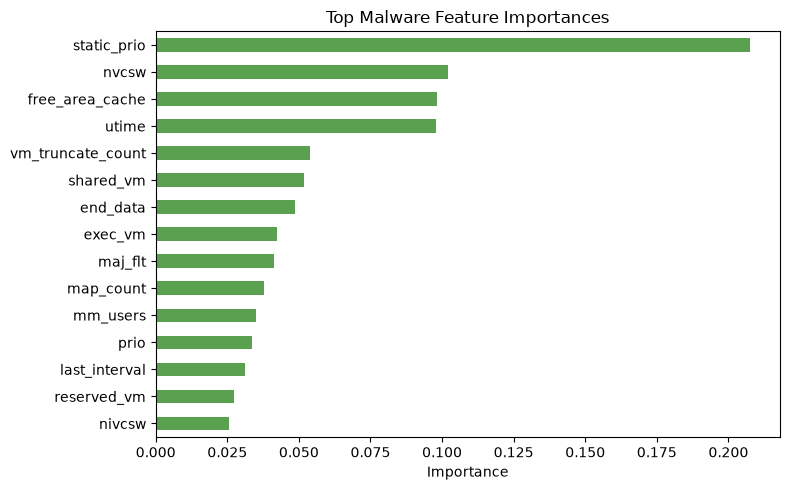

Clustering metrics (silhouette estimated on a reproducible sample):


,silhouette_score_sampled,silhouette_sample_size,adjusted_rand_index_vs_true,normalized_mutual_info_vs_true
0,0.306399,10000,0.004955,0.003911


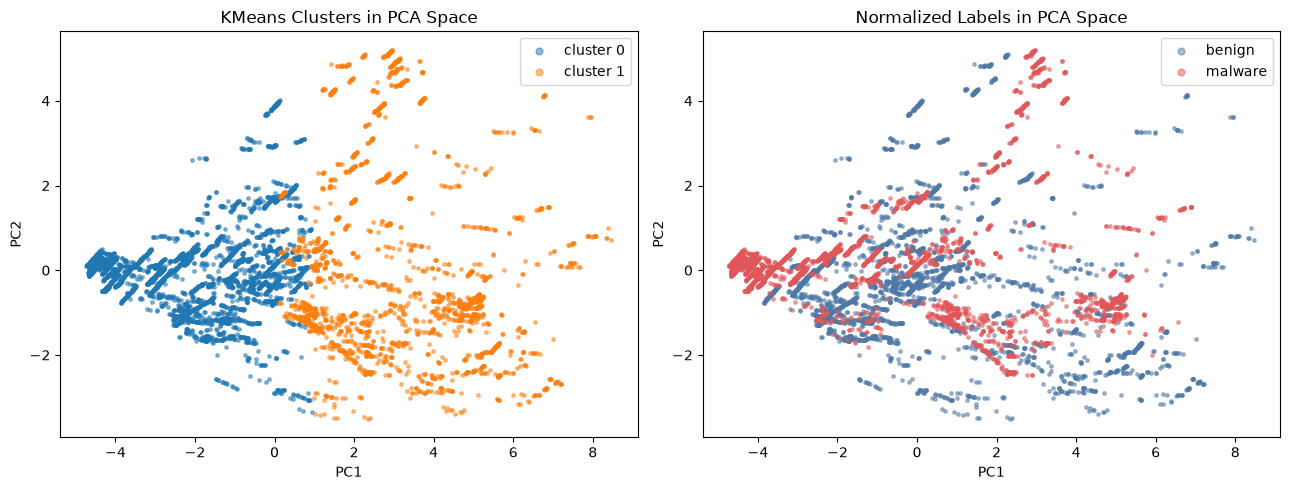

Malware feature count: 33
Interpretation: investigate unexpectedly strong feature/label associations and duplicate patterns before treating a high test score as evidence of generalization.


(                predicted_benign  predicted_malware
 actual_benign              10000                  0
 actual_malware                 0              10000,
                    importance
 static_prio          0.207632
 nvcsw                0.102112
 free_area_cache      0.098148
 utime                0.097960
 vm_truncate_count    0.054027
 shared_vm            0.051919
 end_data             0.048621
 exec_vm              0.042315
 maj_flt              0.041248
 map_count            0.037712,
    silhouette_score_sampled  silhouette_sample_size  \
 0                  0.306399                   10000   
 
    adjusted_rand_index_vs_true  normalized_mutual_info_vs_true  
 0                     0.004955                        0.003911  )

In [9]:
malware_raw = read_csv_with_encoding(DATA_DIR / 'Malware dataset.csv')
if 'classification' not in malware_raw.columns:
    raise KeyError("The malware dataset must contain a 'classification' target column.")

malware_normalized_labels = malware_raw['classification'].map(normalize_binary_label)
malware_valid_label_mask = malware_normalized_labels.notna()
malware_unusable_label_rows = int((~malware_valid_label_mask).sum())

# Remove rows with unusable labels; retain original rows for the audit above.
malware_clean = malware_raw.loc[malware_valid_label_mask].copy()
malware_labels_initial = malware_normalized_labels.loc[malware_valid_label_mask].astype(int).reset_index(drop=True)

malware_non_numeric_columns = malware_clean.drop(
    columns=['hash', 'classification'], errors='ignore'
).select_dtypes(exclude='number').columns.tolist()

malware_features_initial = (
    malware_clean.drop(columns=['hash', 'classification'], errors='ignore')
    .select_dtypes(include='number')
    .reset_index(drop=True)
    .replace([np.inf, -np.inf], np.nan)
)
malware_all_missing_columns = malware_features_initial.columns[
    malware_features_initial.isna().all()
].tolist()
malware_features_initial = malware_features_initial.drop(columns=malware_all_missing_columns)

if malware_features_initial.shape[1] == 0:
    raise ValueError('No usable numeric malware features remain after excluding identifier and target columns.')

malware_missing_feature_cells = int(malware_features_initial.isna().sum().sum())
malware_feature_columns_initial = malware_features_initial.columns.tolist()

# Audit repeated feature vectors. Identical vectors with conflicting labels are excluded as a group;
# identical vectors with the same label are reduced to one example to avoid train/test duplication.
malware_audit_frame = malware_features_initial.copy()
malware_audit_frame['_label'] = malware_labels_initial.to_numpy()
malware_audit_frame['_feature_hash'] = pd.util.hash_pandas_object(
    malware_features_initial, index=False
).astype('uint64').to_numpy()

malware_exact_duplicate_rows = int(
    malware_audit_frame.duplicated(subset=malware_feature_columns_initial + ['_label']).sum()
)
malware_labels_per_feature_hash = malware_audit_frame.groupby('_feature_hash')['_label'].nunique()
malware_conflicting_feature_hashes = set(
    malware_labels_per_feature_hash[malware_labels_per_feature_hash > 1].index
)
malware_conflicting_feature_groups = len(malware_conflicting_feature_hashes)
malware_conflicting_feature_rows_excluded = int(
    malware_audit_frame['_feature_hash'].isin(malware_conflicting_feature_hashes).sum()
)

malware_audit_filtered = malware_audit_frame.loc[
    ~malware_audit_frame['_feature_hash'].isin(malware_conflicting_feature_hashes)
].copy()
malware_duplicate_feature_rows_removed = int(
    malware_audit_filtered.duplicated(subset=malware_feature_columns_initial).sum()
)
malware_audit_deduplicated = malware_audit_filtered.drop_duplicates(
    subset=malware_feature_columns_initial, keep='first'
).copy()

malware_labels = malware_audit_deduplicated['_label'].astype(int).reset_index(drop=True)
malware_features = malware_audit_deduplicated[malware_feature_columns_initial].reset_index(drop=True)
malware_feature_columns = malware_features.columns.tolist()

print('Raw malware label values:')
display(malware_raw['classification'].value_counts(dropna=False).to_frame('rows'))
print(f'Rows excluded for missing or unrecognized labels: {malware_unusable_label_rows:,}')
print(f'Numeric feature columns initially available: {len(malware_feature_columns_initial):,}')
print(f'All-missing numeric columns excluded: {malware_all_missing_columns}')
print(f'Non-numeric columns excluded from modeling: {malware_non_numeric_columns}')
print(f'Missing numeric feature cells before imputation: {malware_missing_feature_cells:,}')
print(f'Exact duplicate feature/label rows observed before deduplication: {malware_exact_duplicate_rows:,}')
print(f'Conflicting identical-feature groups excluded: {malware_conflicting_feature_groups:,}')
print(f'Rows excluded from conflicting feature groups: {malware_conflicting_feature_rows_excluded:,}')
print(f'Repeated feature rows removed after conflict exclusion: {malware_duplicate_feature_rows_removed:,}')
print(f'Usable malware rows after audit and deduplication: {len(malware_features):,}')
print(f'Numeric model features retained: {len(malware_feature_columns):,}')
print('Usable malware class distribution:')
display(malware_labels.value_counts().rename(index={0: 'benign', 1: 'malware'}).to_frame('rows'))

if malware_labels.nunique() != 2:
    raise ValueError('Malware classification requires both normalized classes (0 and 1) after cleaning.')

# Descriptive correlation with the target is a screening signal, not proof of leakage or causality.
malware_corr_frame = malware_features.copy()
malware_corr_frame['_target_label'] = malware_labels.to_numpy()
malware_feature_label_correlations = (
    malware_corr_frame.corr(numeric_only=True)['_target_label']
    .drop('_target_label')
    .dropna()
    .sort_values(key=lambda values: values.abs(), ascending=False)
)
print('Top absolute numeric feature/label correlations (investigate unusually strong values):')
display(malware_feature_label_correlations.head(15).to_frame('pearson_correlation'))

# Plot correlations for a manageable subset of numeric features.
corr_columns = malware_features.columns[:min(12, len(malware_features.columns))]
corr_snapshot = malware_features[corr_columns].corr()
fig, ax = plt.subplots(figsize=(max(7, len(corr_columns) * 0.55), 6))
im = ax.imshow(corr_snapshot, cmap='coolwarm', vmin=-1, vmax=1)
ax.set_title('Malware Feature Correlation (first numeric features)')
ax.set_xticks(range(len(corr_snapshot.columns)))
ax.set_xticklabels(corr_snapshot.columns, rotation=90, fontsize=8)
ax.set_yticks(range(len(corr_snapshot.columns)))
ax.set_yticklabels(corr_snapshot.columns, fontsize=8)
fig.colorbar(im, ax=ax, fraction=0.045)
plt.tight_layout()
plt.show()

# Reproducible 60/20/20 stratified split.
X_trainval_malware, X_test_malware, y_trainval_malware, y_test_malware = train_test_split(
    malware_features, malware_labels,
    test_size=0.20, random_state=RANDOM_STATE, stratify=malware_labels
)
X_train_malware, X_val_malware, y_train_malware, y_val_malware = train_test_split(
    X_trainval_malware, y_trainval_malware,
    test_size=0.25, random_state=RANDOM_STATE, stratify=y_trainval_malware
)

malware_models = {
    'random_forest': Pipeline(steps=[
        ('imputer', SimpleImputer(strategy='median')),
        ('classifier', RandomForestClassifier(
            n_estimators=300, min_samples_leaf=2,
            class_weight='balanced_subsample', n_jobs=-1,
            random_state=RANDOM_STATE
        )),
    ]),
    'decision_tree_baseline': Pipeline(steps=[
        ('imputer', SimpleImputer(strategy='median')),
        ('classifier', DecisionTreeClassifier(
            class_weight='balanced', min_samples_leaf=2,
            random_state=RANDOM_STATE
        )),
    ]),
}

malware_validation_rows = []
for model_name, model_pipeline in malware_models.items():
    model_pipeline.fit(X_train_malware, y_train_malware)
    val_predictions = model_pipeline.predict(X_val_malware)
    val_probabilities = model_pipeline.predict_proba(X_val_malware)[:, 1]
    val_report = classification_report(
        y_val_malware, val_predictions, labels=[0, 1],
        target_names=['benign', 'malware'], output_dict=True, zero_division=0
    )
    malware_validation_rows.append({
        'model': model_name,
        'accuracy': val_report['accuracy'],
        'malware_precision': val_report['malware']['precision'],
        'malware_recall': val_report['malware']['recall'],
        'malware_f1': val_report['malware']['f1-score'],
        'roc_auc': roc_auc_score(y_val_malware, val_probabilities),
    })

malware_validation_df = (
    pd.DataFrame(malware_validation_rows)
    .sort_values('roc_auc', ascending=False)
    .reset_index(drop=True)
)
print('Malware candidate comparison on validation data (not the final test set):')
display(malware_validation_df.round(4))

best_malware_model_name = str(malware_validation_df.iloc[0]['model'])
malware_pipeline = malware_models[best_malware_model_name]

# Refit the selected candidate on all development data; test data remains untouched until final scoring.
malware_pipeline.fit(X_trainval_malware, y_trainval_malware)
malware_predictions = malware_pipeline.predict(X_test_malware)
malware_probabilities = malware_pipeline.predict_proba(X_test_malware)[:, 1]

print(f'Selected malware model by validation ROC-AUC: {best_malware_model_name}')
print('Final held-out malware test classification report:')
print(classification_report(
    y_test_malware, malware_predictions, labels=[0, 1],
    target_names=['benign', 'malware'], zero_division=0
))
print(f'Final malware test ROC-AUC: {roc_auc_score(y_test_malware, malware_probabilities):.4f}')

malware_confusion = pd.DataFrame(
    confusion_matrix(y_test_malware, malware_predictions, labels=[0, 1]),
    index=['actual_benign', 'actual_malware'],
    columns=['predicted_benign', 'predicted_malware'],
)
display(malware_confusion)

malware_split_summary = pd.DataFrame([
    {'partition': 'train', 'rows': len(X_train_malware), 'malware_rate': float(y_train_malware.mean())},
    {'partition': 'validation', 'rows': len(X_val_malware), 'malware_rate': float(y_val_malware.mean())},
    {'partition': 'final_test', 'rows': len(X_test_malware), 'malware_rate': float(y_test_malware.mean())},
])
print('Malware split sizes and positive-class rates:')
display(malware_split_summary)

feature_importance = (
    pd.Series(
        malware_pipeline.named_steps['classifier'].feature_importances_,
        index=malware_feature_columns,
    )
    .sort_values(ascending=False)
    .head(15)
    .to_frame('importance')
)

fig, ax = plt.subplots(figsize=(8, 5))
feature_importance.sort_values('importance').plot(kind='barh', ax=ax, legend=False, color='#59a14f')
ax.set_title('Top Malware Feature Importances')
ax.set_xlabel('Importance')
plt.tight_layout()
plt.show()

# Clustering is exploratory and unsupervised. The true labels are used only to calculate agreement metrics.
malware_imputed = SimpleImputer(strategy='median').fit_transform(malware_features)
malware_scaled = StandardScaler().fit_transform(malware_imputed)

kmeans = KMeans(n_clusters=2, random_state=RANDOM_STATE, n_init=20)
cluster_labels = kmeans.fit_predict(malware_scaled)

silhouette_sample_size = min(10000, len(cluster_labels))
clustering_metrics = {
    'silhouette_score_sampled': float(
        silhouette_score(
            malware_scaled, cluster_labels,
            sample_size=silhouette_sample_size, random_state=RANDOM_STATE
        )
    ),
    'silhouette_sample_size': int(silhouette_sample_size),
    'adjusted_rand_index_vs_true': float(adjusted_rand_score(malware_labels, cluster_labels)),
    'normalized_mutual_info_vs_true': float(normalized_mutual_info_score(malware_labels, cluster_labels)),
}
print('Clustering metrics (silhouette estimated on a reproducible sample):')
display(pd.DataFrame([clustering_metrics]))

pca_2d = PCA(n_components=2, random_state=RANDOM_STATE).fit_transform(malware_scaled)
cluster_view = pd.DataFrame({
    'pc1': pca_2d[:, 0],
    'pc2': pca_2d[:, 1],
    'cluster': cluster_labels,
    'true_label': malware_labels.to_numpy(),
})
sampled_cluster_view = cluster_view.sample(n=min(6000, len(cluster_view)), random_state=RANDOM_STATE)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for cluster_value in sorted(sampled_cluster_view['cluster'].unique()):
    subset = sampled_cluster_view[sampled_cluster_view['cluster'] == cluster_value]
    axes[0].scatter(subset['pc1'], subset['pc2'], s=6, alpha=0.5, label=f'cluster {cluster_value}')
axes[0].set_title('KMeans Clusters in PCA Space')
axes[0].set_xlabel('PC1')
axes[0].set_ylabel('PC2')
axes[0].legend(markerscale=2)

for class_value, color, label_name in [(0, '#4e79a7', 'benign'), (1, '#e15759', 'malware')]:
    subset = sampled_cluster_view[sampled_cluster_view['true_label'] == class_value]
    axes[1].scatter(subset['pc1'], subset['pc2'], s=6, alpha=0.5, color=color, label=label_name)
axes[1].set_title('Normalized Labels in PCA Space')
axes[1].set_xlabel('PC1')
axes[1].set_ylabel('PC2')
axes[1].legend(markerscale=2)
plt.tight_layout()
plt.show()

print(f'Malware feature count: {len(malware_feature_columns)}')
print('Interpretation: investigate unexpectedly strong feature/label associations and duplicate patterns before treating a high test score as evidence of generalization.')
malware_confusion, feature_importance.head(10), pd.DataFrame([clustering_metrics])


## 9. Final Data Validation and Artifact Checks

This section validates cleaned inputs, confirms that normalized duplicate spam text does not cross partitions, checks the malware feature schema, and verifies model serialization. Final test metrics are reported separately from validation metrics used to select candidate models.


In [10]:
spam_model_path = MODEL_DIR / 'spam_detector.joblib'
malware_model_path = MODEL_DIR / 'malware_detector.joblib'
metadata_path = MODEL_DIR / 'model_metadata.json'

# Guard the training and backend-facing outputs against accidental schema or cleaning regressions.
if spam_df[['text', 'label']].isna().any().any():
    raise AssertionError('The cleaned spam frame contains missing text or labels.')
if not set(spam_df['label'].unique()).issubset({0, 1}):
    raise AssertionError('The cleaned spam frame contains labels outside {0, 1}.')
if spam_df['text'].duplicated().any():
    raise AssertionError('Duplicate or conflicting spam text remains after integration.')
if set(normalize_text_key(X_train_text)).intersection(set(normalize_text_key(X_test_text))):
    raise AssertionError('Normalized spam train/test text overlap detected.')
if malware_features.empty or not malware_feature_columns:
    raise AssertionError('No numeric malware features are available for training.')
if not malware_labels.isin([0, 1]).all():
    raise AssertionError('The malware training labels are not binary.')

joblib.dump(spam_pipeline, spam_model_path)
joblib.dump(malware_pipeline, malware_model_path)

metadata = {
    'random_state': RANDOM_STATE,
    'use_multilingual_augmentation': USE_MULTILINGUAL_AUGMENTATION,
    'data_sources': DATA_SOURCES,
    'method_types_used': ['classification', 'clustering'],
    'spam': {
        'rows': int(len(spam_df)),
        'sources': spam_df['source'].value_counts().to_dict(),
        'selected_model': best_spam_model_name,
        'validation_model_comparison': spam_validation_df.to_dict(orient='records'),
        'final_test_metrics': {
            'accuracy': float(spam_test_report['accuracy']),
            'spam_precision': float(spam_test_report['spam']['precision']),
            'spam_recall': float(spam_test_report['spam']['recall']),
            'spam_f1': float(spam_test_report['spam']['f1-score']),
            'roc_auc': float(roc_auc_score(y_test_text, spam_probabilities)),
        },
    },
    'malware': {
        'rows': int(len(malware_features)),
        'features': malware_feature_columns,
        'selected_model': best_malware_model_name,
        'validation_model_comparison': malware_validation_df.to_dict(orient='records'),
        'final_test_metrics': {
            'accuracy': float(malware_pipeline.score(X_test_malware, y_test_malware)),
            'roc_auc': float(roc_auc_score(y_test_malware, malware_probabilities)),
        },
        'clustering_metrics': {
            'silhouette_score': clustering_metrics['silhouette_score_sampled'],
            'silhouette_sample_size': clustering_metrics['silhouette_sample_size'],
            'adjusted_rand_index_vs_true': clustering_metrics['adjusted_rand_index_vs_true'],
            'normalized_mutual_info_vs_true': clustering_metrics['normalized_mutual_info_vs_true'],
        },
    },
    'data_quality': {
        'spam': {
            'source_quality': spam_source_quality.to_dict(orient='records'),
            'usable_records_before_integration': int(len(spam_records)),
            'conflicting_text_groups': int(spam_conflict_group_count),
            'conflicting_records_excluded': int(spam_conflict_rows_excluded),
            'exact_duplicate_rows_removed_after_conflict_exclusion': int(spam_exact_duplicates_removed),
            'normalized_duplicate_rows_removed_after_conflict_exclusion': int(spam_normalized_duplicates_removed),
            'training_rows_after_cleaning': int(len(spam_df)),
        },
        'malware': {
            'unusable_label_rows_excluded': int(malware_unusable_label_rows),
            'usable_rows': int(len(malware_features)),
            'numeric_feature_count': int(len(malware_feature_columns)),
            'missing_numeric_feature_cells': int(malware_missing_feature_cells),
            'exact_duplicate_feature_label_rows_reported': int(malware_exact_duplicate_rows),
            'non_numeric_columns_excluded': malware_non_numeric_columns,
        },
    },
}

with metadata_path.open('w', encoding='utf-8') as file:
    json.dump(metadata, file, indent=2, allow_nan=False)


def predict_spam(messages):
    message_series = pd.Series(messages, dtype='string')
    probabilities = spam_pipeline.predict_proba(message_series)[:, 1]
    predictions = spam_pipeline.predict(message_series)
    return pd.DataFrame(
        {
            'text': message_series,
            'spam_probability': probabilities,
            'predicted_label': np.where(predictions == 1, 'spam', 'ham'),
        }
    )


def predict_malware(feature_frame: pd.DataFrame):
    aligned = feature_frame.reindex(columns=malware_feature_columns)
    probabilities = malware_pipeline.predict_proba(aligned)[:, 1]
    predictions = malware_pipeline.predict(aligned)
    return pd.DataFrame(
        {
            'malware_probability': probabilities,
            'predicted_label': np.where(predictions == 1, 'malware', 'benign'),
        }
    )

# Round-trip checks verify serialization without changing the backend's documented filenames.
reloaded_spam_pipeline = joblib.load(spam_model_path)
reloaded_malware_pipeline = joblib.load(malware_model_path)
assert np.array_equal(
    reloaded_spam_pipeline.predict(X_test_text.head(3)),
    spam_pipeline.predict(X_test_text.head(3)),
)
assert np.array_equal(
    reloaded_malware_pipeline.predict(X_test_malware.head(3)),
    malware_pipeline.predict(X_test_malware.head(3)),
)
with metadata_path.open('r', encoding='utf-8') as file:
    saved_metadata = json.load(file)
assert saved_metadata['data_sources'] == DATA_SOURCES
assert saved_metadata['spam']['rows'] == len(spam_df)
assert saved_metadata['malware']['features'] == malware_feature_columns

print('Saved and reloaded model artifacts:')
print(spam_model_path)
print(malware_model_path)
print(metadata_path)
print('Artifact round-trip and metadata checks passed.')

print('\nSample spam predictions:')
display(
    predict_spam([
        'Claim your free prize now!',
        'Reminder: project meeting moved to 3 PM.',
    ])
)

print('\nSample malware predictions (first 3 rows of held-out set):')
display(predict_malware(X_test_malware.head(3)))

Saved and reloaded model artifacts:
D:\COS30049\group-project-spr-2026-grp2_7\data\trained_models\spam_detector.joblib
D:\COS30049\group-project-spr-2026-grp2_7\data\trained_models\malware_detector.joblib
D:\COS30049\group-project-spr-2026-grp2_7\data\trained_models\model_metadata.json
Artifact round-trip and metadata checks passed.

Sample spam predictions:


,text,spam_probability,predicted_label
0,Claim your free prize now!,0.991907,spam
1,Reminder: project meeting moved to 3 PM.,0.159279,ham



Sample malware predictions (first 3 rows of held-out set):


,malware_probability,predicted_label
0,0.999985,malware
1,0.000000,benign
2,0.000000,benign


## 10. Summary of Data Quality Findings and Evaluation Limits

Use the output of the final summary cell as the source of reported counts. The dataset origins remain unverified unless independent repository evidence establishes them. The metrics describe only the local datasets and this reproducible split; they do not establish performance on unseen real-world spam or malware.

The spam candidates are selected on validation ROC-AUC and evaluated once on the final test set. Malware candidates follow the same procedure. If malware test performance remains unusually high, investigate feature meaning, dataset construction, duplicate patterns, and possible target leakage before drawing conclusions.


In [11]:
print(f'Local CSV files inspected: {len(file_inventory)}')
print('\nSPAM DATA')
print(f'Source records before integration: {len(spam_records):,}')
print(f'Exact duplicate rows removed after conflict filtering: {spam_exact_duplicates_removed:,}')
print(f'Normalized duplicate rows removed after conflict filtering: {spam_normalized_duplicates_removed:,}')
print(f'Conflicting normalized-text groups: {spam_conflict_group_count:,}')
print(f'Records excluded for contradictory normalized-text labels: {spam_conflict_rows_excluded:,}')
print(f'Final spam rows: {len(spam_df):,}')
print(f'Spam model selected on validation data: {best_spam_model_name}')
print(f'Spam validation ROC-AUC: {float(spam_validation_df.iloc[0]["roc_auc"]):.4f}')
print(f'Spam final test ROC-AUC: {roc_auc_score(y_test_text, spam_probabilities):.4f}')
print('Spam final test confusion matrix:')
display(spam_confusion)

if spam_conflict_group_count:
    print('Spam interpretation: contradictory normalized-text groups were excluded before splitting.')
else:
    print('Spam interpretation: no conflicting labels were found under the documented lowercase/whitespace normalization.')

print('\nMALWARE DATA')
print(f'Usable malware rows after audit/deduplication: {len(malware_features):,}')
print(f'Rows excluded for unusable labels: {malware_unusable_label_rows:,}')
print(f'Missing numeric feature cells before imputation: {malware_missing_feature_cells:,}')
print(f'Exact duplicate feature/label rows initially observed: {malware_exact_duplicate_rows:,}')
print(f'Conflicting identical-feature groups excluded: {malware_conflicting_feature_groups:,}')
print(f'Rows excluded for conflicting feature groups: {malware_conflicting_feature_rows_excluded:,}')
print(f'Duplicate feature rows removed: {malware_duplicate_feature_rows_removed:,}')
print(f'Numeric features retained: {len(malware_feature_columns):,}')
print(f'Malware model selected on validation data: {best_malware_model_name}')
print(f'Malware validation ROC-AUC: {float(malware_validation_df.iloc[0]["roc_auc"]):.4f}')
print(f'Malware final test ROC-AUC: {roc_auc_score(y_test_malware, malware_probabilities):.4f}')
print('Malware final test confusion matrix:')
display(malware_confusion)
print('Malware clustering metrics:')
display(pd.DataFrame([clustering_metrics]))

unverified_sources = [
    source['local_file'] for source in DATA_SOURCES
    if source['provenance_status'] != 'verified'
]
print('\nDataset origins still unverified:', unverified_sources)
print('No processed CSV dataset was written; original CSV inputs were read only.')
print('Notebook reached the final summary cell. Review all warnings and metrics above before using them in the report.')


Local CSV files inspected: 7

SPAM DATA
Source records before integration: 16,913
Exact duplicate rows removed after conflict filtering: 5,982
Normalized duplicate rows removed after conflict filtering: 6,147
Conflicting normalized-text groups: 0
Records excluded for contradictory normalized-text labels: 0
Final spam rows: 10,766
Spam model selected on validation data: logistic_regression_char_tfidf
Spam validation ROC-AUC: 0.9957
Spam final test ROC-AUC: 0.9971
Spam final test confusion matrix:


,predicted_ham,predicted_spam
actual_ham,1729,17
actual_spam,16,392


Spam interpretation: no conflicting labels were found under the documented lowercase/whitespace normalization.

MALWARE DATA
Usable malware rows after audit/deduplication: 100,000
Rows excluded for unusable labels: 0
Missing numeric feature cells before imputation: 0
Exact duplicate feature/label rows initially observed: 0
Conflicting identical-feature groups excluded: 0
Rows excluded for conflicting feature groups: 0
Duplicate feature rows removed: 0
Numeric features retained: 33
Malware model selected on validation data: random_forest
Malware validation ROC-AUC: 1.0000
Malware final test ROC-AUC: 1.0000
Malware final test confusion matrix:


,predicted_benign,predicted_malware
actual_benign,10000,0
actual_malware,0,10000


Malware clustering metrics:


,silhouette_score_sampled,silhouette_sample_size,adjusted_rand_index_vs_true,normalized_mutual_info_vs_true
0,0.306399,10000,0.004955,0.003911



Dataset origins still unverified: ['mail_data.csv', 'emails.csv', 'data-augmented.csv', 'Malware dataset.csv']
No processed CSV dataset was written; original CSV inputs were read only.
Notebook reached the final summary cell. Review all warnings and metrics above before using them in the report.
